Running Model A (Standard) with Adam...
Running Model A (Standard) with SGD...
Running Model A (Standard) with SGD + Momentum...
Running Model B (Lightweight) with Adam...
Running Model B (Lightweight) with SGD...
Running Model B (Lightweight) with SGD + Momentum...


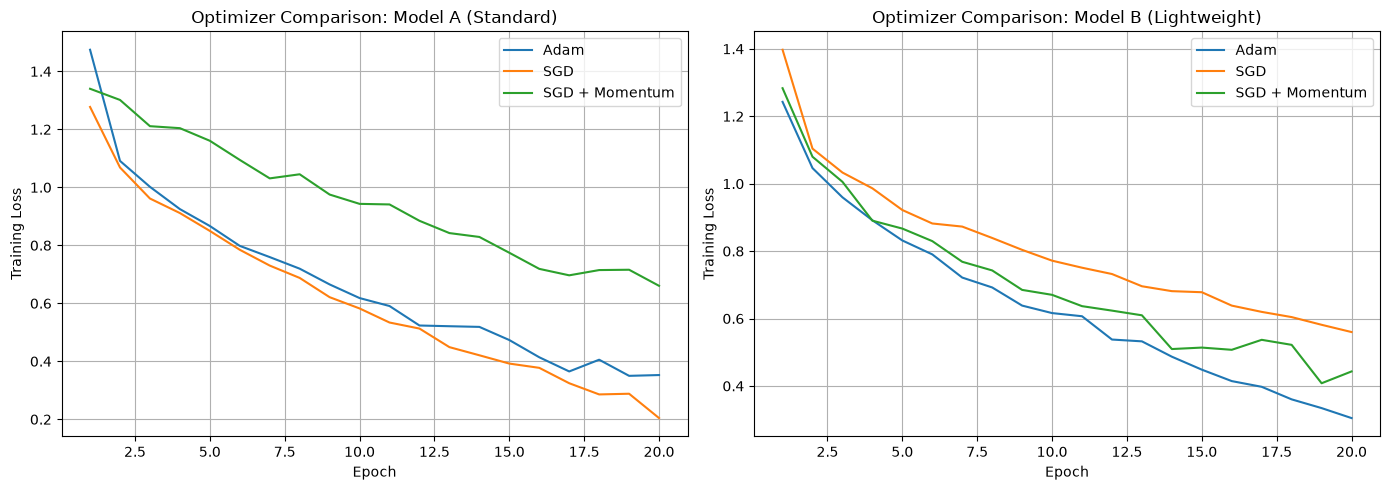

In [7]:
import os
import sys
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

# Path resolution
PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), ".."))
if PROJECT_ROOT not in sys.path:
    sys.path.append(PROJECT_ROOT)

from models.model_a import ModelA
from models.model_b import ModelB

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

TRAIN_DIR = os.path.join(PROJECT_ROOT, "data", "train")
train_dataset = datasets.ImageFolder(root=TRAIN_DIR, transform=transform)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)

# Define optimizer constructors
optimizer_factories = {
    'Adam': lambda params: optim.Adam(params, lr=0.001),
    'SGD': lambda params: optim.SGD(params, lr=0.01),
    'SGD + Momentum': lambda params: optim.SGD(params, lr=0.01, momentum=0.9)
}

models_dict = {
    'Model A (Standard)': ModelA,
    'Model B (Lightweight)': ModelB
}

results = {}
criterion = nn.CrossEntropyLoss()

for model_name, model_cls in models_dict.items():
    results[model_name] = {}
    for opt_name, opt_factory in optimizer_factories.items():
        print(f"Running {model_name} with {opt_name}...")
        model = model_cls(num_classes=5).to(device)
        optimizer = opt_factory(model.parameters())
        
        epoch_losses = []
        for epoch in range(20):
            model.train()
            running_loss = 0.0
            for inputs, labels in train_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                optimizer.zero_grad()
                outputs = model(inputs)
                loss = criterion(outputs, labels)
                loss.backward()
                optimizer.step()
                running_loss += loss.item() * inputs.size(0)
            
            epoch_loss = running_loss / len(train_dataset)
            epoch_losses.append(epoch_loss)
            
        results[model_name][opt_name] = epoch_losses

# Plotting Comparison Graphs
fig, axs = plt.subplots(1, 2, figsize=(14, 5))

for i, (model_name, opt_results) in enumerate(results.items()):
    for opt_name, losses in opt_results.items():
        axs[i].plot(range(1, 21), losses, label=opt_name)
    axs[i].set_title(f'Optimizer Comparison: {model_name}')
    axs[i].set_xlabel('Epoch')
    axs[i].set_ylabel('Training Loss')
    axs[i].legend()
    axs[i].grid(True)

plt.tight_layout()
plt.savefig('optimizer_comparison_models_a_and_b.png')
plt.show()